# SVD image reconstruction lab

First run the supplied worksheet on **`ejaj.jpg`**, the local image supplied with this repository. Then analyze **one georeferenced Sentinel-2 GeoTIFF** containing Seattle, nearby forest, and Puget Sound. We compare three equally sized terrain crops from that one scene. The first image is analyzed at its native 554×554 resolution; each satellite crop is 256×256 at native 10 m resolution.

From this repository run `uv sync`, then **`uv run jupyter server`**. Open `lab1/algebra.ipynb` and select **Restart Kernel and Run All Cells**. No Colab or Google Drive setup is required. The GeoTIFF is included; the side script `uv run python lab1/download_satellite.py` downloads it if missing.

**Terminology:** the worksheet calls the retained values “eigenvalues.” SVD returns **singular values** $\sigma_i$. Their squares are the eigenvalues of $A^T A$ (up to zero padding). Here $k$ counts singular components.


In [1]:
from pathlib import Path
import csv
import json

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from skimage.metrics import structural_similarity

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})


In [2]:
import sys

ROOT = Path.cwd()
if (ROOT / "lab1" / "ejaj.jpg").is_file():
    ROOT = ROOT / "lab1"
if not (ROOT / "ejaj.jpg").is_file():
    raise FileNotFoundError("Start Jupyter from the ml-for-space repository or its lab1 directory.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
RESULTS = ROOT / "results"
RESULTS.mkdir(exist_ok=True)


def grayscale(path):
    with Image.open(path) as image:
        return np.asarray(image.convert("L"), dtype=np.float64)


def reconstruct(u, s, vh, k, start=0):
    # start is zero based: start=9 begins with the 10th singular component.
    stop = min(start + k, len(s))
    return (u[:, start:stop] * s[start:stop]) @ vh[start:stop, :]


def quality(a, b):
    # Score the actual floating-point reconstruction, before display clipping.
    mse = float(np.mean((a - b) ** 2))
    psnr = float("inf") if mse < 1e-20 else 10 * np.log10(255.0 ** 2 / mse)
    ssim = structural_similarity(a, b, data_range=255.0)
    return float(psnr), float(ssim)


def energy_rank(s, fraction):
    return int(np.searchsorted(np.cumsum(s ** 2) / np.sum(s ** 2), fraction) + 1)


def show_image(ax, a, title):
    # A shared intensity scale prevents autoscaling from hiding lost brightness.
    ax.imshow(np.clip(a, 0, 255), cmap="gray", vmin=0, vmax=255, interpolation="nearest")
    ax.set_title(title)
    ax.axis("off")


def save_figure(name):
    plt.savefig(RESULTS / name, bbox_inches="tight")
    plt.show()


## 1. Run the supplied worksheet on the local image

An RGB image is a three-dimensional array (height × width × channels). Ordinary image-matrix SVD requires a two-dimensional matrix. Converting to grayscale supplies one luminance matrix; a color-preserving alternative would decompose each channel separately. Applying NumPy SVD directly to an RGB array instead treats its last two dimensions as matrices, which is not the intended spatial decomposition.


Local image: ejaj.jpg; grayscale matrix shape: (554, 554)


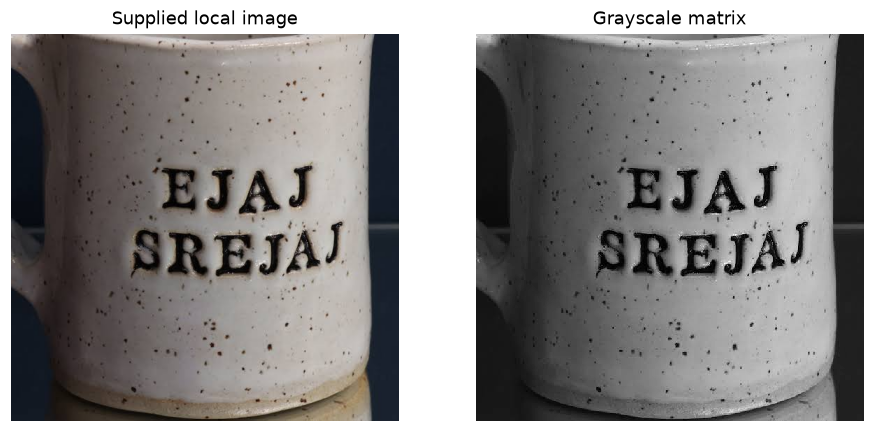

In [3]:
img = Image.open(ROOT / "ejaj.jpg")
imggray = img.convert("L")
imgmat = np.asarray(imggray, dtype=np.float64)
print(f"Local image: ejaj.jpg; grayscale matrix shape: {imgmat.shape}")
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(img)
axes[0].set_title("Supplied local image")
axes[0].axis("off")
show_image(axes[1], imgmat, "Grayscale matrix")
save_figure("local_original.png")


### Singular value decomposition

For $A=U\Sigma V^T$, NumPy returns `U`, the descending singular values, and `Vh` ($V^T$). `full_matrices=False` avoids unused columns. First reconstruct the image using only its largest singular value.


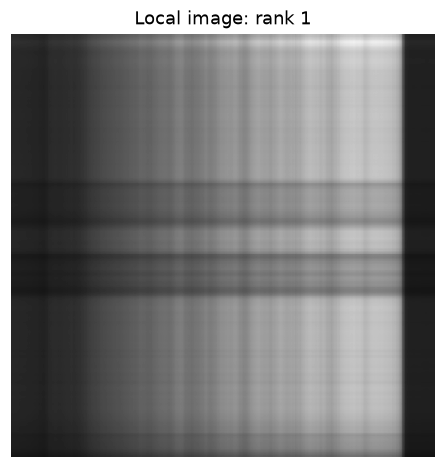

In [4]:
U, sigma, Vh = np.linalg.svd(imgmat, full_matrices=False)
reconstimg = reconstruct(U, sigma, Vh, k=1)
fig, ax = plt.subplots(figsize=(5, 5))
show_image(ax, reconstimg, "Local image: rank 1")
save_figure("local_rank1.png")


The singular-value curve tells us how rapidly the components decay. Cumulative squared singular values measure retained Frobenius energy. A high energy percentage alone does **not** guarantee that fine detail looks unchanged: the mean brightness can dominate this measure.


U, singular values, Vh shapes: (554, 554) (554,) (554, 554)


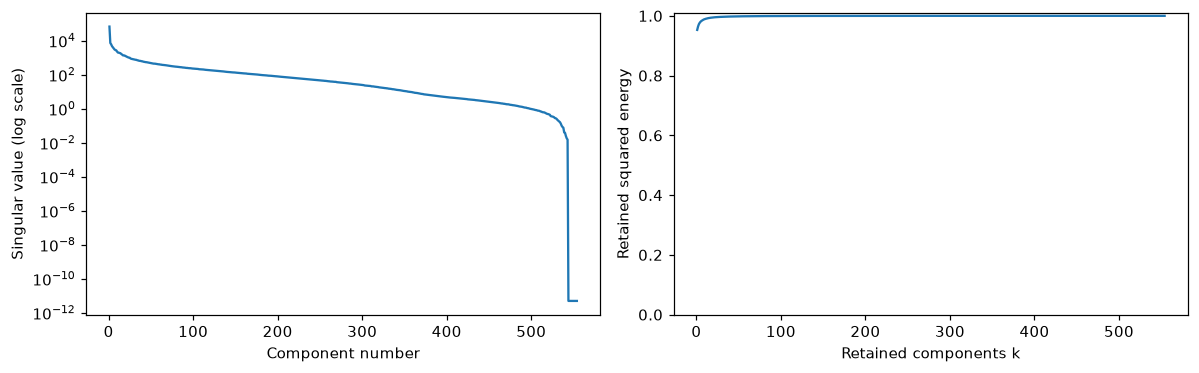

In [5]:
print("U, singular values, Vh shapes:", U.shape, sigma.shape, Vh.shape)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].semilogy(np.arange(1, len(sigma) + 1), np.maximum(sigma, 1e-12))
axes[0].set(xlabel="Component number", ylabel="Singular value (log scale)")
axes[1].plot(np.arange(1, len(sigma) + 1), np.cumsum(sigma ** 2) / np.sum(sigma ** 2))
axes[1].set(xlabel="Retained components k", ylabel="Retained squared energy", ylim=(0, 1.01))
fig.tight_layout()
save_figure("local_spectrum.png")


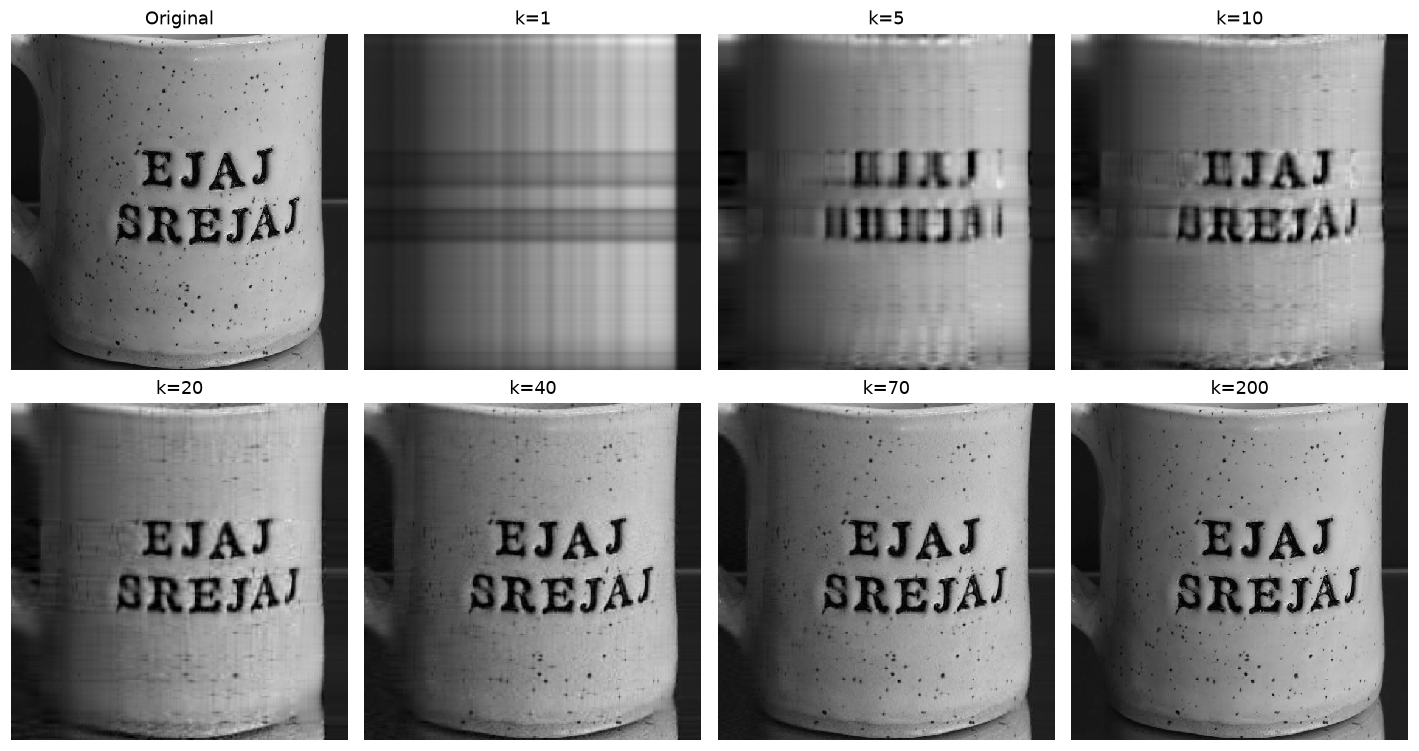

In [6]:
i, j = min(70, len(sigma)), 0
reconstimg = reconstruct(U, sigma, Vh, k=i - j, start=j)
local_ranks = sorted(set([1, 5, 10, 20, 40, i, 100, 200, len(sigma)]))
local_ranks = [k for k in local_ranks if k <= len(sigma)]
local_rows = []
fig, axes = plt.subplots(2, 4, figsize=(13, 7))
show_image(axes.flat[0], imgmat, "Original")
for ax, k in zip(list(axes.flat)[1:], [1, 5, 10, 20, 40, i, 200]):
    show_image(ax, reconstruct(U, sigma, Vh, k), f"k={k}")
fig.tight_layout()
save_figure("local_reconstructions.png")
for k in local_ranks:
    psnr, ssim = quality(imgmat, reconstruct(U, sigma, Vh, k))
    local_rows.append({"k": k, "PSNR (dB)": psnr, "SSIM": ssim})


### Local image measurements

| k | PSNR (dB) | SSIM |
| --- | --- | --- |
| 1 | 19.5728 | 0.7095 |
| 5 | 23.3806 | 0.7708 |
| 10 | 25.9646 | 0.7951 |
| 20 | 29.1438 | 0.8284 |
| 40 | 32.7481 | 0.8783 |
| 70 | 36.3529 | 0.9264 |
| 100 | 39.3205 | 0.9557 |
| 200 | 48.7382 | 0.9927 |
| 554 | inf | 1.0000 |


### Local image observations

For ejaj.jpg, 99% of squared energy needs 11 components, and 99.9% needs 70. The worksheet's k=70 reconstruction has SSIM=0.9264 and PSNR=36.35 dB. Low ranks recover the broad mug shape; increasing k restores the lettering, speckles and edges. Removing the first one or two components discards dominant intensity/shape information, so a reconstruction from the remainder loses important low-rank structure.


## 2. Satellite image: how many components are enough?

We use **one Sentinel-2B L2A true-color GeoTIFF, acquired 29 August 2024**, item `S2B_10TET_20240829_0_L2A`. The downloader reads a Seattle-area geographic window from the [public Cloud Optimized GeoTIFF](https://sentinel-cogs.s3.us-west-2.amazonaws.com/sentinel-s2-l2a-cogs/10/T/ET/2024/8/S2B_10TET_20240829_0_L2A/TCI.tif), retaining its **EPSG:32610 CRS, affine transform, and native 10 m pixels**. [Source metadata](https://earth-search.aws.element84.com/v1/collections/sentinel-2-l2a/items/S2B_10TET_20240829_0_L2A) are recorded in `data/satellite/source.json`. Contains modified Copernicus Sentinel data (2024), distributed through Earth Search / AWS Open Data.

From this single image we take 256×256 crops centered on forest near Cougar Mountain, an urban Seattle neighborhood, and coastal water in Puget Sound. The overview shows where these crops come from. Puget Sound is a marine inlet, not an open-ocean sample. These are geographically selected representative regions, not official land-cover labels. All crops use the same grayscale conversion, pixel resolution and intensity range.

**Operational criterion for “good enough”:** the smallest $k$ satisfying **SSIM ≥ 0.99 and PSNR ≥ 40 dB** against the grayscale original. This is a strict, reproducible quality proxy, not proof that every viewer will see no difference. The reconstruction panels and difference maps allow visual inspection. Energy thresholds are reported separately.

The GeoTIFF contains display-scaled RGB, not raw spectral reflectance. Conclusions concern grayscale appearance at this scale, not multispectral or scientific information preservation.


GeoTIFF: 3184 × 3030; 3 bands; CRS=EPSG:32610; pixel size=(10.0, 10.0) m


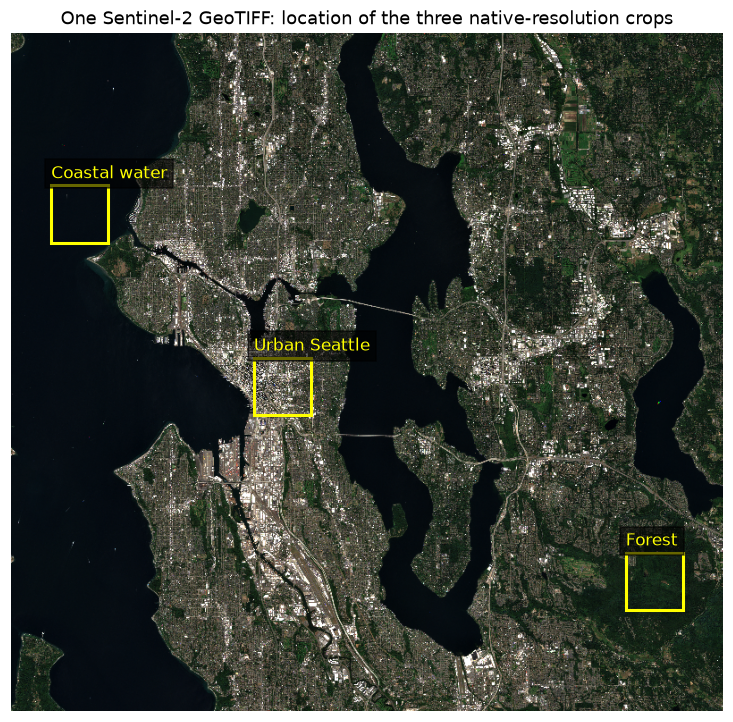

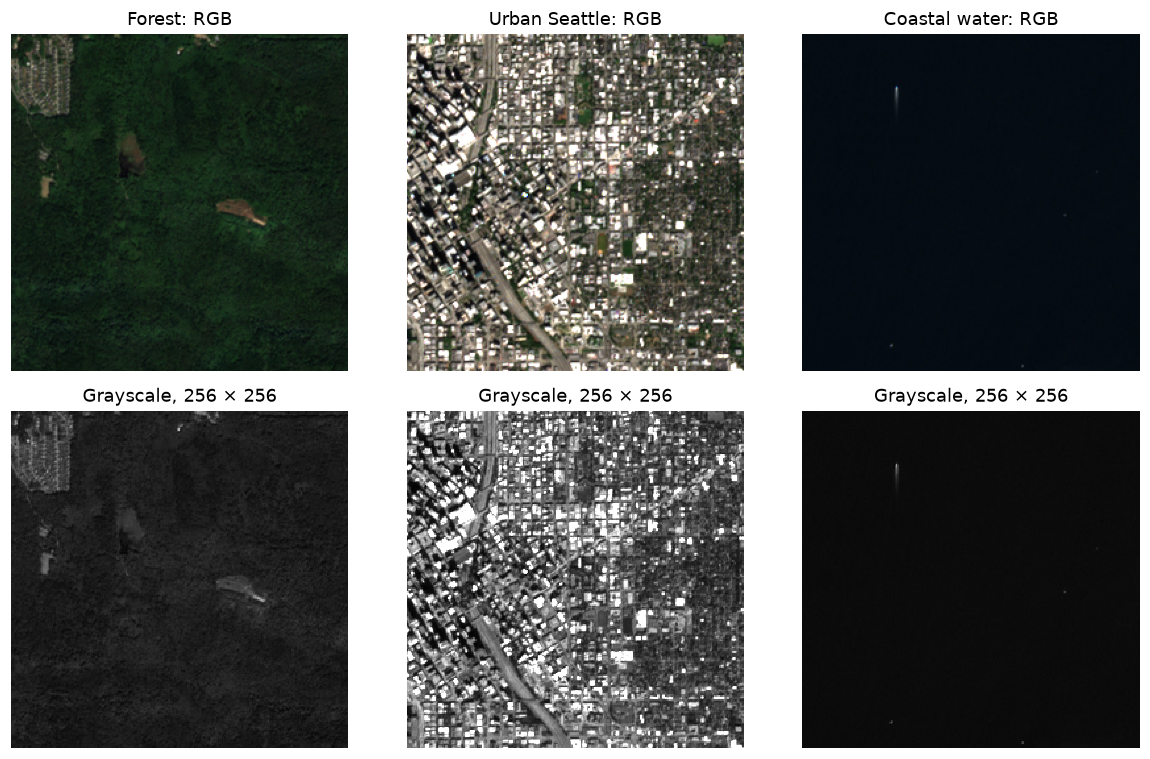

In [7]:
import rasterio
from rasterio.warp import transform
from rasterio.windows import Window
from matplotlib.patches import Rectangle
from download_satellite import download_image

satellite_path = download_image(ROOT)
terrain_names = {"Forest": "Forest", "Urban": "Urban Seattle", "Water": "Coastal water"}
centers = {"Forest": (-122.10, 47.53), "Urban": (-122.32, 47.61), "Water": (-122.44, 47.68)}
CROP_SIZE = 256
samples = {}
crop_metadata = []
with rasterio.open(satellite_path) as source:
    print(f"GeoTIFF: {source.width} × {source.height}; {source.count} bands; "
          f"CRS={source.crs}; pixel size={source.res} m")
    assert source.crs is not None and source.count == 3
    overview = source.read([1, 2, 3])[:, ::4, ::4].transpose(1, 2, 0)
    fig, ax = plt.subplots(figsize=(9, 8))
    ax.imshow(overview)
    for terrain, (lon, lat) in centers.items():
        xs, ys = transform("EPSG:4326", source.crs, [lon], [lat])
        row, col = source.index(xs[0], ys[0])
        window = Window(col - CROP_SIZE // 2, row - CROP_SIZE // 2, CROP_SIZE, CROP_SIZE)
        assert window.col_off >= 0 and window.row_off >= 0
        assert window.col_off + CROP_SIZE <= source.width and window.row_off + CROP_SIZE <= source.height
        rgb = source.read([1, 2, 3], window=window).transpose(1, 2, 0)
        assert np.all(source.dataset_mask(window=window) > 0), "Crop includes nodata"
        a = np.asarray(Image.fromarray(rgb).convert("L"), dtype=np.float64)
        samples[terrain] = {"terrain": terrain, "a": a, "rgb": rgb,
                            "svd": np.linalg.svd(a, full_matrices=False)}
        crop_metadata.append({"terrain": terrain, "center_lon": lon, "center_lat": lat,
                              "column": int(window.col_off), "row": int(window.row_off),
                              "width": CROP_SIZE, "height": CROP_SIZE})
        ax.add_patch(Rectangle((window.col_off / 4, window.row_off / 4),
                              CROP_SIZE / 4, CROP_SIZE / 4, fill=False, edgecolor="yellow", linewidth=2))
        ax.text(window.col_off / 4, window.row_off / 4 - 8, terrain_names[terrain],
                color="yellow", fontsize=11, bbox={"facecolor": "black", "alpha": 0.6})
    ax.set_title("One Sentinel-2 GeoTIFF: location of the three native-resolution crops")
    ax.axis("off")
    save_figure("satellite_overview.png")
(RESULTS / "crop_locations.json").write_text(json.dumps(crop_metadata, indent=2) + "\n")
fig, axes = plt.subplots(2, 3, figsize=(11, 7))
for col, (name, sample) in enumerate(samples.items()):
    axes[0, col].imshow(sample["rgb"])
    axes[0, col].set_title(f"{terrain_names[name]}: RGB")
    axes[0, col].axis("off")
    show_image(axes[1, col], sample["a"], "Grayscale, 256 × 256")
fig.tight_layout()
save_figure("satellite_inputs.png")


In [8]:
SSIM_TARGET, PSNR_TARGET = 0.99, 40.0
rows, curves = [], {}
for name, sample in samples.items():
    a = sample["a"]
    u, s, vh = sample["svd"]
    approximation = np.zeros_like(a)
    curve = []
    for index in range(len(s)):
        approximation += s[index] * np.outer(u[:, index], vh[index, :])
        psnr, ssim = quality(a, approximation)
        curve.append({"k": index + 1, "PSNR (dB)": psnr, "SSIM": ssim})
    curves[name] = curve
    chosen = next(point for point in curve
                  if point["SSIM"] >= SSIM_TARGET and point["PSNR (dB)"] >= PSNR_TARGET)
    rows.append({"image": name, "terrain": sample["terrain"], "k*": chosen["k"],
                 "k*/256 (%)": 100 * chosen["k"] / len(s),
                 "k (99% energy)": energy_rank(s, 0.99),
                 "k (99.9% energy)": energy_rank(s, 0.999),
                 "PSNR (dB)": chosen["PSNR (dB)"], "SSIM": chosen["SSIM"]})
with (RESULTS / "satellite_metrics.csv").open("w", newline="") as stream:
    writer = csv.DictWriter(stream, fieldnames=list(rows[0]))
    writer.writeheader()
    writer.writerows(rows)


### Satellite measurements

| image | k* | k*/256 (%) | k (99% energy) | k (99.9% energy) | PSNR (dB) | SSIM |
| --- | --- | --- | --- | --- | --- | --- |
| Forest | 131 | 51.1719 | 49 | 131 | 47.7493 | 0.9900 |
| Urban | 170 | 66.4062 | 80 | 148 | 40.0628 | 0.9971 |
| Water | 4 | 1.5625 | 2 | 86 | 49.6760 | 0.9902 |


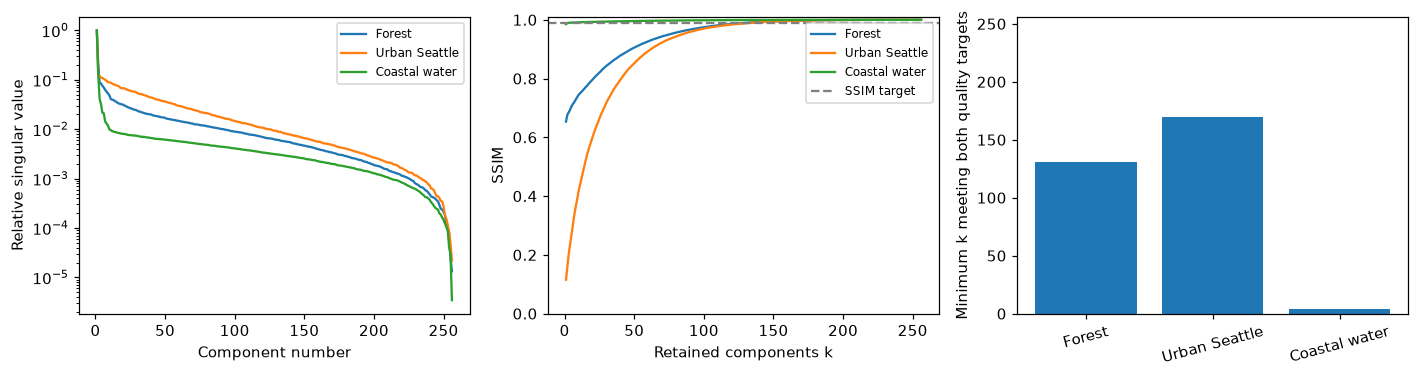

In [9]:
summary = [{"terrain": terrain_names[row["terrain"]], "k*": row["k*"],
            "fraction (%)": row["k*/256 (%)"], "PSNR (dB)": row["PSNR (dB)"], "SSIM": row["SSIM"]}
           for row in rows]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for terrain in terrain_names:
    s = samples[terrain]["svd"][1]
    axes[0].semilogy(np.arange(1, CROP_SIZE + 1), np.maximum(s / s[0], 1e-12), label=terrain_names[terrain])
    axes[1].plot(np.arange(1, CROP_SIZE + 1), [point["SSIM"] for point in curves[terrain]], label=terrain_names[terrain])
axes[0].set(xlabel="Component number", ylabel="Relative singular value")
axes[1].axhline(SSIM_TARGET, color="gray", linestyle="--", label="SSIM target")
axes[1].set(xlabel="Retained components k", ylabel="SSIM", ylim=(0, 1.01))
axes[2].bar([row["terrain"] for row in summary], [row["k*"] for row in summary])
axes[2].set(ylabel="Minimum k meeting both quality targets", ylim=(0, CROP_SIZE))
axes[2].tick_params(axis="x", labelrotation=15)
axes[0].legend(fontsize=8)
axes[1].legend(fontsize=8)
fig.tight_layout()
save_figure("terrain_comparison.png")


### Terrain comparison

| terrain | k* | fraction (%) | PSNR (dB) | SSIM |
| --- | --- | --- | --- | --- |
| Forest | 131 | 51.1719 | 47.7493 | 0.9900 |
| Urban Seattle | 170 | 66.4062 | 40.0628 | 0.9971 |
| Coastal water | 4 | 1.5625 | 49.6760 | 0.9902 |


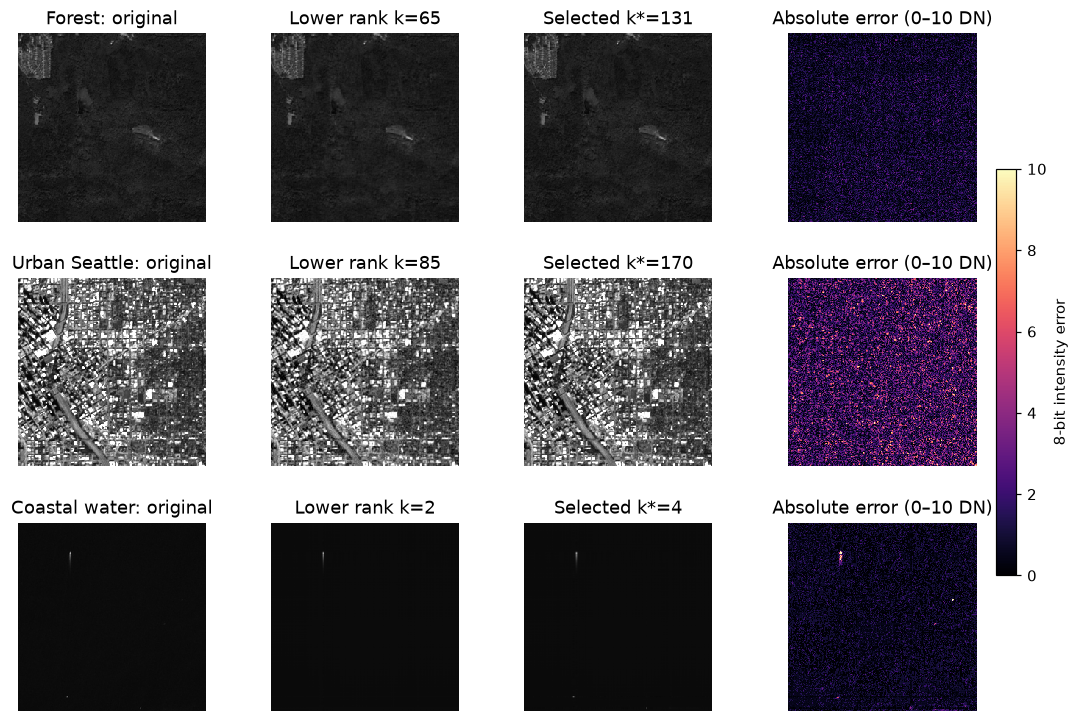

In [10]:
fig, axes = plt.subplots(3, 4, figsize=(12, 8))
for index, terrain in enumerate(terrain_names):
    name = terrain
    sample = samples[name]
    a = sample["a"]
    k = next(row["k*"] for row in rows if row["image"] == name)
    low_k = max(1, k // 2)
    selected = reconstruct(*sample["svd"], k)
    show_image(axes[index, 0], a, f"{terrain_names[terrain]}: original")
    show_image(axes[index, 1], reconstruct(*sample["svd"], low_k), f"Lower rank k={low_k}")
    show_image(axes[index, 2], selected, f"Selected k*={k}")
    error = axes[index, 3].imshow(np.abs(a - selected), cmap="magma", vmin=0, vmax=10, interpolation="nearest")
    axes[index, 3].set_title("Absolute error (0–10 DN)")
    axes[index, 3].axis("off")
fig.colorbar(error, ax=axes[:, 3], shrink=0.6, label="8-bit intensity error")
fig.subplots_adjust(hspace=0.3, wspace=0.2, right=0.86)
save_figure("satellite_reconstructions.png")


## 3. Does starting at the 10th component improve the image?

For a fair comparison, keep the **same number $k=20$** of components: components **1–20** versus **10–29** (one-based numbering, Python slice `9:29`). The wording “10th through $(k+10)$th” literally includes **$k+1$** components; we also test **10–30** so both interpretations are visible.

The leading-$k$ truncated SVD minimizes Frobenius reconstruction error among matrices of rank at most $k$. Replacing its leading components with later ones therefore cannot improve that error. Skipping them often emphasizes residual texture, but loses the dominant image structure and brightness. SSIM is a separate metric; the theorem concerns squared pixel error, not every possible perceptual score.


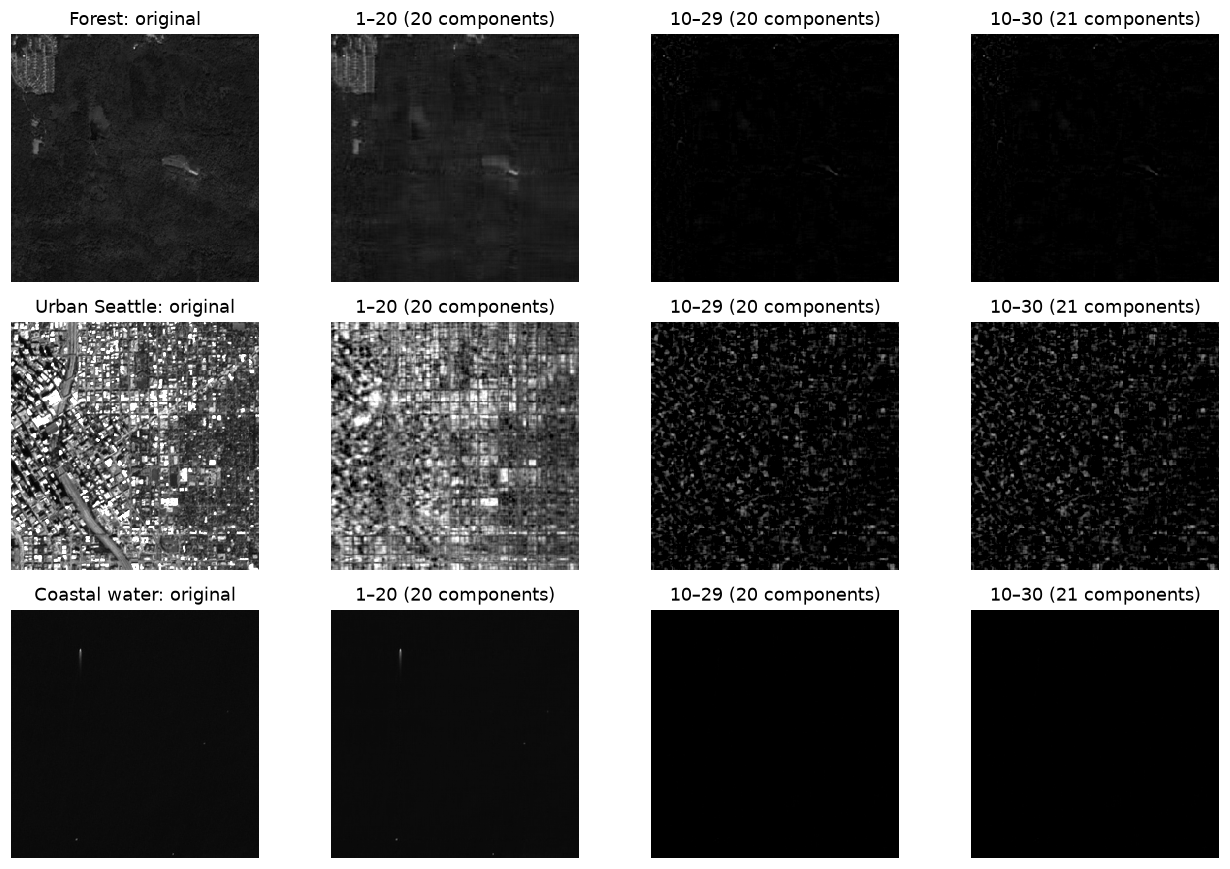

In [11]:
k = 20
shift_rows = []
fig, axes = plt.subplots(3, 4, figsize=(12, 8))
for index, terrain in enumerate(terrain_names):
    name = terrain
    sample = samples[name]
    a = sample["a"]
    show_image(axes[index, 0], a, f"{terrain_names[terrain]}: original")
    for col, (label, count, start) in enumerate([
        ("1–20 (20 components)", k, 0),
        ("10–29 (20 components)", k, 9),
        ("10–30 (21 components)", k + 1, 9),
    ], start=1):
        approximation = reconstruct(*sample["svd"], count, start)
        psnr, ssim = quality(a, approximation)
        relative_error = float(np.linalg.norm(a - approximation) / np.linalg.norm(a))
        shift_rows.append({"image": name, "components": label,
                           "relative Frobenius error": relative_error,
                           "PSNR (dB)": psnr, "SSIM": ssim})
        show_image(axes[index, col], approximation, label)
fig.tight_layout()
save_figure("shifted_components.png")
with (RESULTS / "shifted_metrics.csv").open("w", newline="") as stream:
    writer = csv.DictWriter(stream, fieldnames=list(shift_rows[0]))
    writer.writeheader()
    writer.writerows(shift_rows)


### Leading versus shifted components

| image | components | relative Frobenius error | PSNR (dB) | SSIM |
| --- | --- | --- | --- | --- |
| Forest | 1–20 (20 components) | 0.1510 | 34.1680 | 0.7961 |
| Forest | 10–29 (20 components) | 0.9903 | 17.8336 | 0.0003 |
| Forest | 10–30 (21 components) | 0.9901 | 17.8358 | 0.0003 |
| Urban | 1–20 (20 components) | 0.2950 | 16.8755 | 0.5999 |
| Urban | 10–29 (20 components) | 0.9601 | 6.6249 | -0.0081 |
| Urban | 10–30 (21 components) | 0.9589 | 6.6356 | -0.0083 |
| Water | 1–20 (20 components) | 0.0584 | 51.8382 | 0.9929 |
| Water | 10–29 (20 components) | 0.9993 | 27.1754 | 0.0503 |
| Water | 10–30 (21 components) | 0.9993 | 27.1757 | 0.0503 |


## Observations and conclusions

These observations use the measurements from this run. The three crops come from one scene, with one crop per terrain, so this is a descriptive comparison rather than a statistical claim about all forests, cities, or oceans. Texture, contrast, orientation, resolution, and the selected quality criterion all affect $k$.


### 1. How many components are good enough?

For ejaj.jpg, 99% of squared energy needs 11 components, and 99.9% needs 70. The worksheet's k=70 reconstruction has SSIM=0.9264 and PSNR=36.35 dB. Low ranks recover the broad mug shape; increasing k restores the lettering, speckles and edges. Removing the first one or two components discards dominant intensity/shape information, so a reconstruction from the remainder loses important low-rank structure.

For the satellite crops, the SSIM ≥ 0.99 and PSNR ≥ 40 dB criterion gives:

- **Forest**: **131/256** components (51.2%), SSIM=0.9900, PSNR=47.75 dB.
- **Urban Seattle**: **170/256** components (66.4%), SSIM=0.9971, PSNR=40.06 dB.
- **Coastal water**: **4/256** components (1.6%), SSIM=0.9902, PSNR=49.68 dB.

### 2. Should the leading components be skipped?

No. In these examples the 10–29 and 10–30 reconstructions lose most of the image brightness and structure and have much larger relative errors. They contain residual detail, not a better reconstruction. The leading-k SVD is optimal for Frobenius error at the same rank. All panels use a fixed 0–255 scale; independent contrast stretching would hide this loss.

### 3. How does terrain change the required rank?

In this scene, **Coastal water** needs the fewest components (4), and **Urban Seattle** the most (170). Smooth intensity fields concentrate information in fewer components, while irregular fine detail requires more. Terrain labels alone do not determine compressibility. The lower-rank panels, selected panels and error maps allow visual checking of the quality proxy. This does not prove universal perceptual indistinguishability; it measures grayscale appearance at native 10 m resolution. The water crop is Puget Sound, a marine inlet. With one crop per terrain from one acquisition, these results should not be generalized statistically.
